# AI Data Centre Portfolio: Out-of-Sample Validation

This is the second half of a two-part project. The first notebook, `AI_DataCenter_Thesis_Analysis.ipynb`, builds the universe, decomposes returns into factors, optimises portfolios and projects forward. It produces encouraging numbers, and it contains several biases that I identified in place but did not remove.

This notebook asks what survives when they are removed.

The structure is deliberate. Research and validation are different activities with different incentives, and running them in the same file invites the researcher to adjust the model until the validation passes. Separating them means the validation has a fixed target.

## What is done differently here

A temporal train/test split with an embargo, so no parameter used in the test period was estimated with knowledge of it. Walk-forward expanding-window estimation, so the optimiser at time $t$ sees only data through $t$. Transaction costs on every rebalance. And a set of corrections for the fact that more than one strategy was tried: block bootstrap confidence intervals, the Probabilistic Sharpe Ratio, the Deflated Sharpe Ratio, and the Harvey-Liu haircut.

## What came out

I expected test-period performance to be worse than train-period performance. It was considerably better: a Sharpe ratio of 1.30 in the test period against -0.62 in the walk-forward months of the training period. That is not evidence of leakage. The training period's out-of-sample months are 2021 and 2022, which contain the rate shock that hit long-duration growth stocks and REITs hardest, and the test period is the 2023 to 2025 AI rally. The comparison is dominated by which regime each window happened to contain, and a single split cannot separate the strategy from the regime. That is the strongest argument in the notebook for moving to many splits rather than one.

The test-period Sharpe ratio is probably positive (PSR 0.97). It is not significant once the four strategies tried are accounted for (DSR 0.85), it is not distinguishable from SPY (paired difference 0.25, p = 0.50), and equal weighting achieved nearly the same Sharpe ratio. Each of those is reported below with its derivation.

## Contents

0. Setup
1. Data acquisition
2. Temporal train/test split
3. Walk-forward out-of-sample validation
4. Statistical significance
5. Strategy comparison
6. Weight evolution
7. Risk analysis
8. Summary

## 0. Setup

The analysis logic lives in `src/` rather than in the notebook. Three reasons: the functions are unit-testable in a way notebook cells are not, the same code is shared with the exploratory notebook so the two cannot silently diverge, and a reader can audit the implementation of the Deflated Sharpe Ratio without scrolling through output.


In [1]:
import sys, os, warnings
# src/ sits beside this notebook, so no path manipulation is needed
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from src.config import *
from src.data import DataLoader
from src.optimization import (
    max_sharpe_portfolio, min_var_portfolio, shrink_covariance,
    portfolio_stats, efficient_frontier, black_litterman,
)
from src.backtesting import WalkForwardBacktest, BacktestConfig, run_strategy_suite
from src.validation import WalkForwardValidator, SignificanceTests, OverfitDiagnostics
from src.analytics import perf_report, compare_strategies, var_analysis
from src.visualization import (
    setup_style, plot_train_test_equity, plot_bootstrap_sharpe,
    plot_train_test_comparison, plot_psr_summary,
    plot_weight_evolution, plot_strategy_comparison_table,
)

setup_style()
print("All modules loaded successfully.")

All modules loaded successfully.


## 1. Data acquisition

Same universe and same price source as the exploratory notebook, loaded through the same `DataLoader`. Nothing is re-specified here, because any difference between the two notebooks at this stage would confound the comparison that is the entire point of the exercise.

Names with fewer than 36 months of history are dropped. The threshold is a compromise: covariance estimation needs observations, but excluding everything short-lived biases the universe toward survivors. At 36 months the constraint binds on the Asian operators and the thematic ETFs, both of which list late in the sample.


In [2]:
loader = DataLoader(cache_dir='./data_cache')

all_tickers_with_bench = ALL_TICKERS + [BENCHMARK]
prices = loader.load_prices(all_tickers_with_bench, START_DATE, END_DATE)
daily_returns, monthly_returns = loader.compute_returns(prices)

ACTIVE_TICKERS = [t for t in ALL_TICKERS if t in monthly_returns.columns
                  and monthly_returns[t].notna().sum() >= 36]

print(f"Active universe: {len(ACTIVE_TICKERS)} tickers")
print(f"Monthly returns: {monthly_returns.index[0].strftime('%Y-%m')} to "
      f"{monthly_returns.index[-1].strftime('%Y-%m')} ({len(monthly_returns)} months)")

Loaded frozen snapshot: 20/20 tickers, 1799 trading days (2019-01-02 to 2026-02-27)
Active universe: 19 tickers
Monthly returns: 2019-02 to 2026-02 (85 months)


## 2. Temporal train/test split

This is the design decision that everything else depends on.

| Period | Range | Role |
|---|---|---|
| Train | 2019-01 to 2022-12 | Parameter estimation inside the walk-forward loop |
| Embargo | 2023-01 | Discarded entirely |
| Test | 2023-02 to 2026-03 | Never touched during development |

### Why an embargo

Financial time series are serially dependent. A covariance matrix estimated on a 24-month window ending in December 2022 contains information about January 2023, because volatility clusters and the January observation is correlated with the ones immediately preceding it. Splitting at a single instant lets that dependence leak across the boundary.

The embargo discards a block of observations at the join so the two sides are separated by more than one time step. Lopez de Prado (2018) formalises this as purging and embargoing, and shows that cross-validation without it systematically overstates out-of-sample performance in exactly the way a practitioner would least want.

One month is a short embargo. It is appropriate for a 24-month estimation window at monthly frequency, where the dominant dependence is at the one to three month scale, and it costs little sample. For daily data with a long lookback it would be inadequate.

### Why temporal rather than random

$k$-fold cross-validation with random folds is standard in machine learning and invalid here. Randomly assigning months to folds means a model can be trained on June and September 2021 and tested on July 2021, which is to say trained on the future to predict the past. The only valid split for a time series respects the arrow of time.


In [3]:
train_monthly, test_monthly = loader.split_by_date(
    monthly_returns, train_end=TRAIN_END, test_start=TEST_START
)

print(f"\nTrain/Test ratio: {len(train_monthly)}/{len(test_monthly)} months "
      f"({len(train_monthly)/(len(train_monthly)+len(test_monthly)):.0%} / "
      f"{len(test_monthly)/(len(train_monthly)+len(test_monthly)):.0%})")

Train: 2019-02 to 2022-12 (47 obs)
Test:  2023-02 to 2026-02 (37 obs)

Train/Test ratio: 47/37 months (56% / 44%)


## 3. Walk-forward out-of-sample validation

The validator runs an expanding window across the full sample: estimate on everything available up to month $t$, optimise, hold for one month, record the realised return, extend the window, repeat. The resulting return series is partitioned into its train-period and test-period portions after the fact.

### Expanding rather than rolling

An expanding window uses all history to date; a rolling window uses a fixed trailing length. Expanding gives more observations and therefore lower estimation variance, at the cost of weighting a 2019 regime equally with a 2025 one. Rolling adapts faster and estimates worse. I use expanding here because with only about 85 monthly observations in total, estimation error dominates adaptation speed. On a longer sample I would argue the other way, and this is the sort of choice that ought to be pre-registered rather than selected after seeing both.

### What the comparison shows

Both halves of the output are genuinely out of sample in the sense that no parameter was fitted on the return it predicts. The difference is that the train-period half covers the window during which the strategy was being designed, and the test-period half does not. The gap between them is a direct estimate of how much of the performance came from the design process rather than from the strategy.

That quantity is reported below as Sharpe decay, $1 - \mathrm{SR}_{\text{test}}/\mathrm{SR}_{\text{train}}$. A decay near zero means the edge survived; a decay near one means it was fitted.

The ratio has a failure mode that this sample triggers. It is only interpretable when the training Sharpe ratio is positive. With a negative denominator it flips sign, so a strategy that did far better out of sample is reported as catastrophic decay: the original code printed 308% and labelled the overfitting risk HIGH for a strategy whose Sharpe ratio went from -0.62 to 1.30. The diagnostic now reports the decay as undefined in that case. More generally, a train/test comparison over two windows of three or four years each compares regimes at least as much as it compares fitted against unfitted performance.

### Universe selection

The investable universe is the 15 names with the highest Sharpe ratio, ranked on the **training period only**. This matters more than any other single design choice in the notebook. The research notebook ranks on the full sample, so the names it keeps are partly chosen for having done well during the period it later reports as out of sample. A walk-forward loop that re-estimates parameters honestly but inherits a universe chosen with hindsight is still contaminated, and nothing in its output would show it.

A consequence worth stating: the train-period half of the walk-forward output is still affected by selection, since those months were used to rank. Only the test-period half is clean with respect to every decision, which is why the test period is the one that gets reported.

### Missing data

At each rebalance the optimiser sees only names with a complete return history inside the estimation window and a realised return in the holding month. DTCR, which lists in October 2020, simply enters the investable set once it has enough history. The alternative, dropping every month in which any name is missing, would cut nearly two years from the front of the sample for every other name. Any month in which the optimiser fails and equal weights are used instead is counted and reported in the diagnostics rather than absorbed silently.

In [4]:
# ── Universe selection on TRAINING data only ──
#
# The research notebook ranks names by Sharpe ratio over the full sample and
# keeps the top 15, which leaks the test period into the universe. Here the
# ranking uses only months up to TRAIN_END, so nothing about 2023 onward can
# influence which names are eligible. Names need at least 24 training months
# to be ranked at all.

train_mr = monthly_returns.loc[:TRAIN_END]
MIN_TRAIN_OBS = 24
eligible = [t for t in ACTIVE_TICKERS if train_mr[t].notna().sum() >= MIN_TRAIN_OBS]
excluded = sorted(set(ACTIVE_TICKERS) - set(eligible))

sharpes = {t: (train_mr[t].mean() * 12 - RF_ANNUAL) / (train_mr[t].std() * np.sqrt(12))
           for t in eligible}
portfolio_tickers = sorted(sharpes, key=sharpes.get, reverse=True)[:15]

print(f"Ranked on {train_mr.index[0]:%Y-%m} to {train_mr.index[-1]:%Y-%m} only")
if excluded:
    print(f"Too little training history to rank: {excluded}")
print(f"Portfolio universe: {len(portfolio_tickers)} tickers")
print(f"Tickers: {', '.join(portfolio_tickers)}")

Ranked on 2019-02 to 2022-12 only
Portfolio universe: 15 tickers
Tickers: ETN, SBGSY, JCI, ANET, CAT, EQIX, MRVL, IRM, GNRC, HON, VRT, AMT, CCI, GDS, CSCO


In [5]:
# ── Run walk-forward with Ledoit-Wolf shrinkage ──
validator = WalkForwardValidator(
    min_train_months=WF_MIN_TRAIN_MONTHS,
    expanding=WF_EXPANDING,
    cov_method='ledoit_wolf',     # Shrinkage estimator — reduces estimation error
    max_weight=MAX_WEIGHT,        # 15% single-name cap
    rf_annual=RF_ANNUAL,
    transaction_cost_bps=TRANSACTION_COST_BPS,
    slippage_bps=SLIPPAGE_BPS,
)

print("Running walk-forward OOS validation...")
wf_result = validator.run(
    monthly_returns, portfolio_tickers,
    train_end=TRAIN_END, test_start=TEST_START,
)

diag = wf_result['diagnostics']

print(f"\n{'='*60}")
print(f"  WALK-FORWARD OOS RESULTS")
print(f"{'='*60}")
print(f"  {'Metric':<25} {'Train OOS':>12} {'Test OOS':>12}")
print(f"  {'-'*49}")
print(f"  {'Sharpe Ratio':<25} {diag['train_sharpe']:>12.2f} {diag['test_sharpe']:>12.2f}")
print(f"  {'CAGR':<25} {diag['train_cagr']:>11.2%} {diag['test_cagr']:>11.2%}")
print(f"  {'Max Drawdown':<25} {diag['train_max_dd']:>11.2%} {diag['test_max_dd']:>11.2%}")
print(f"  {'Avg Turnover':<25} {diag['train_turnover_avg']:>11.2%} {diag['test_turnover_avg']:>11.2%}")
print(f"  {'Months':<25} {diag['train_months']:>12d} {diag['test_months']:>12d}")
print(f"  {'-'*49}")
if diag['sharpe_decay'] is None:
    print(f"  {'Sharpe Decay':<25} {'undefined':>12}  (train Sharpe <= 0)")
print(f"  {'Optimiser fallbacks':<25} {diag['optimiser_fallbacks']:>12d}")
if diag['sharpe_decay'] is not None:
    print(f"  {'Sharpe Decay':<25} {diag['sharpe_decay']:>11.2%}")
    risk = ("LOW" if diag['sharpe_decay'] < 0.25 else
            "MODERATE" if diag['sharpe_decay'] < 0.50 else "HIGH")
    print(f"  {'Overfitting Risk':<25} {risk:>12}")
print(f"{'='*60}")

Running walk-forward OOS validation...



  WALK-FORWARD OOS RESULTS
  Metric                       Train OOS     Test OOS
  -------------------------------------------------
  Sharpe Ratio                     -0.62         1.30
  CAGR                          -15.05%      38.32%
  Max Drawdown                  -41.50%     -27.59%
  Avg Turnover                   10.78%       5.96%
  Months                              23           37
  -------------------------------------------------
  Sharpe Decay                 undefined  (train Sharpe <= 0)
  Optimiser fallbacks                  0


### 3.1 Train against test equity curves

Plotted on one axis so the change at the boundary is visible rather than inferred from a table.

The break here is in the opposite direction to the usual overfitting signature. The curve falls through 2022 and rises steeply from 2023. Read alongside the benchmark, most of that shape is the market environment rather than the strategy: the training-period months were spent in a drawdown that hit this sector harder than the index, and the test period coincides with the AI-driven rerating of exactly the names this universe holds.

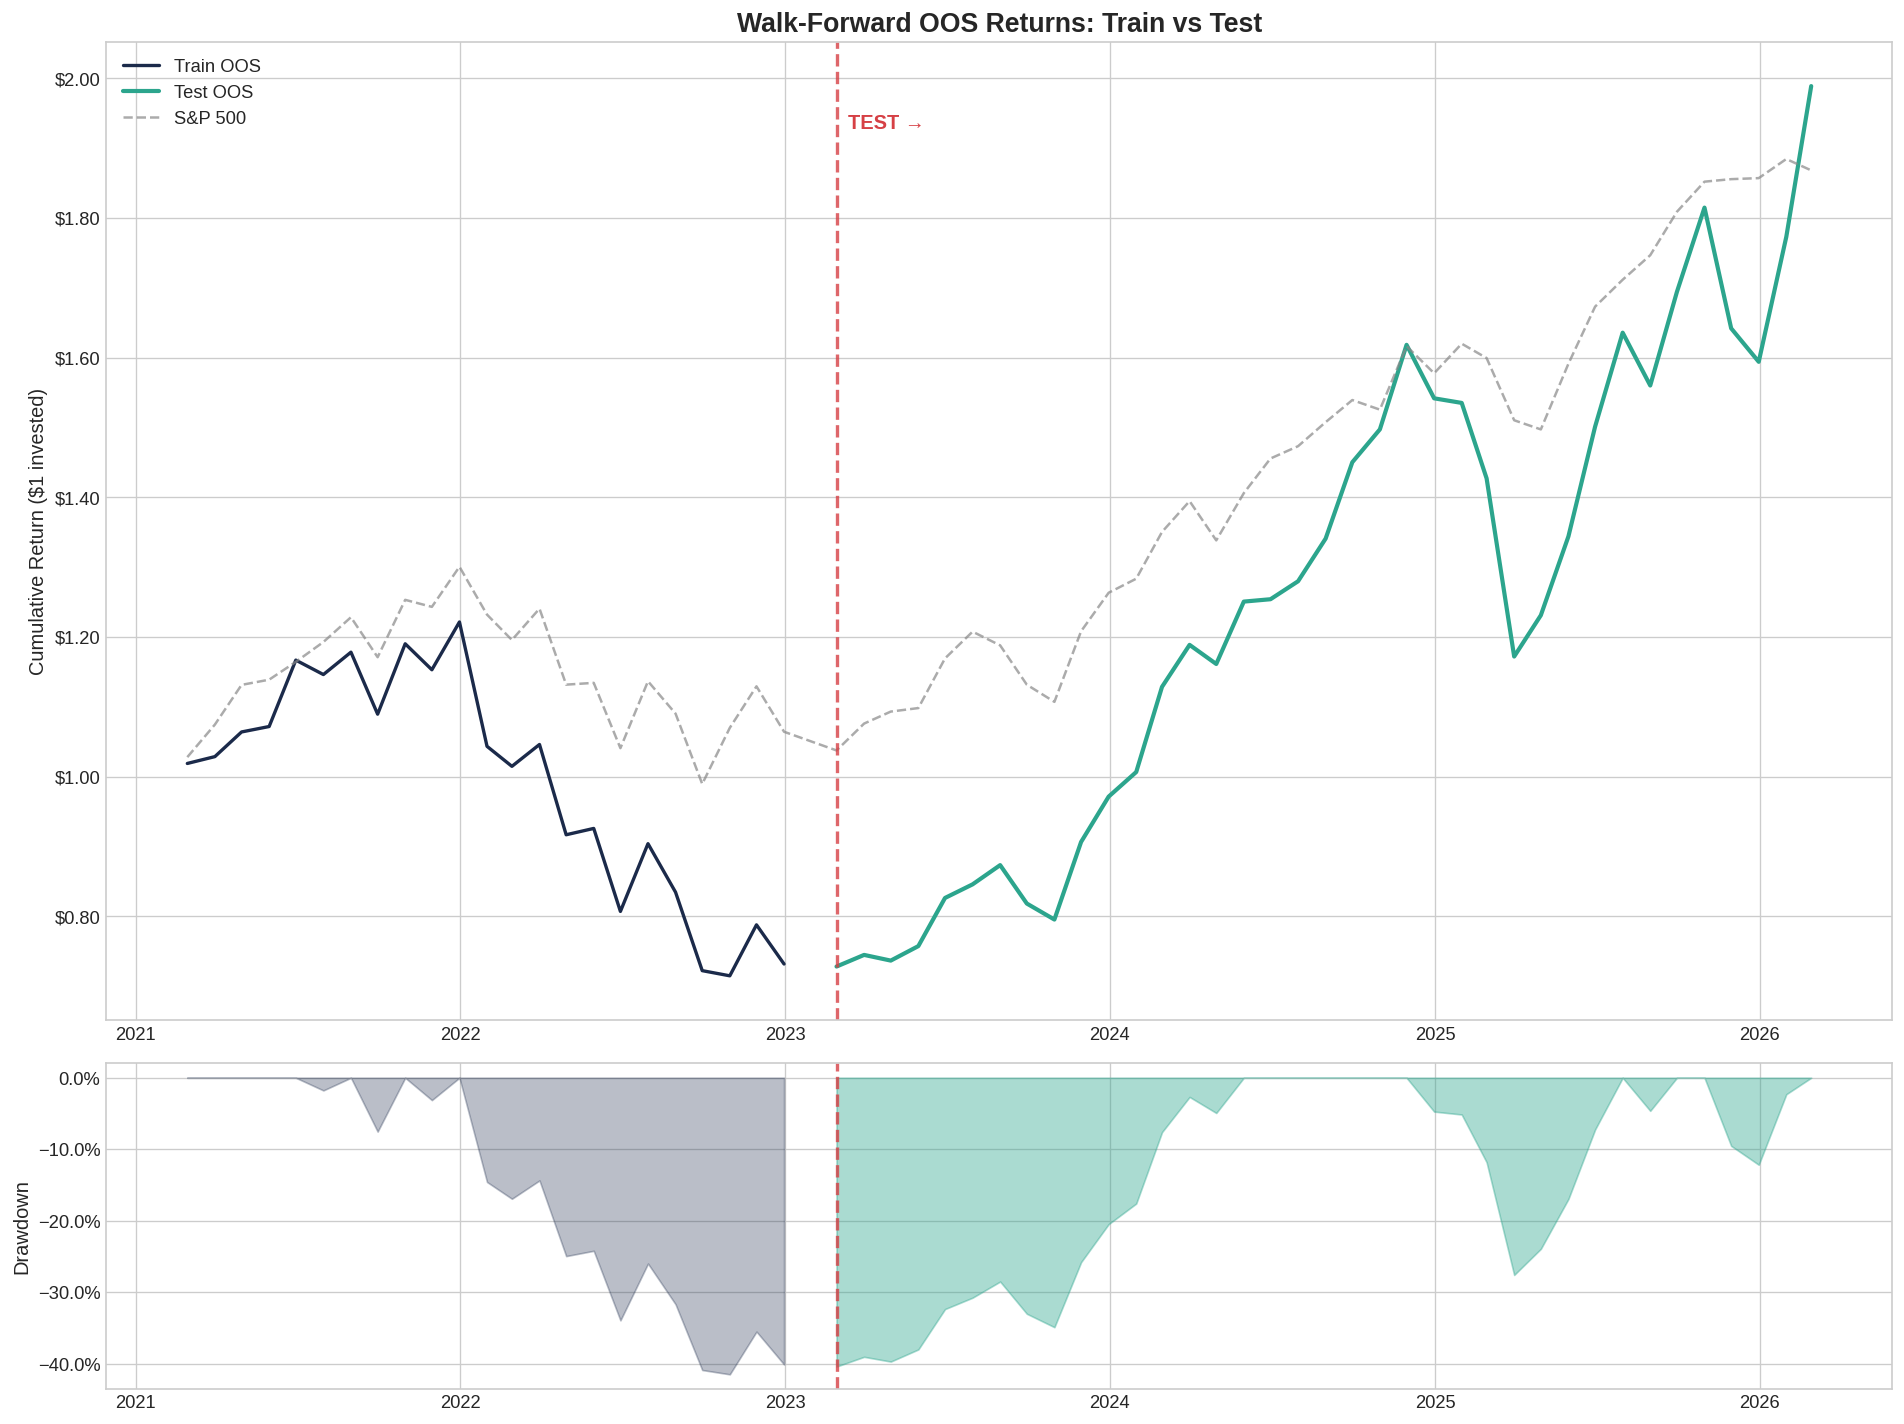

In [6]:
bench_full = monthly_returns[BENCHMARK].reindex(wf_result['full_oos_returns'].index)

fig = plot_train_test_equity(
    wf_result['oos_returns_train'],
    wf_result['oos_returns_test'],
    benchmark_returns=bench_full,
)
plt.show()

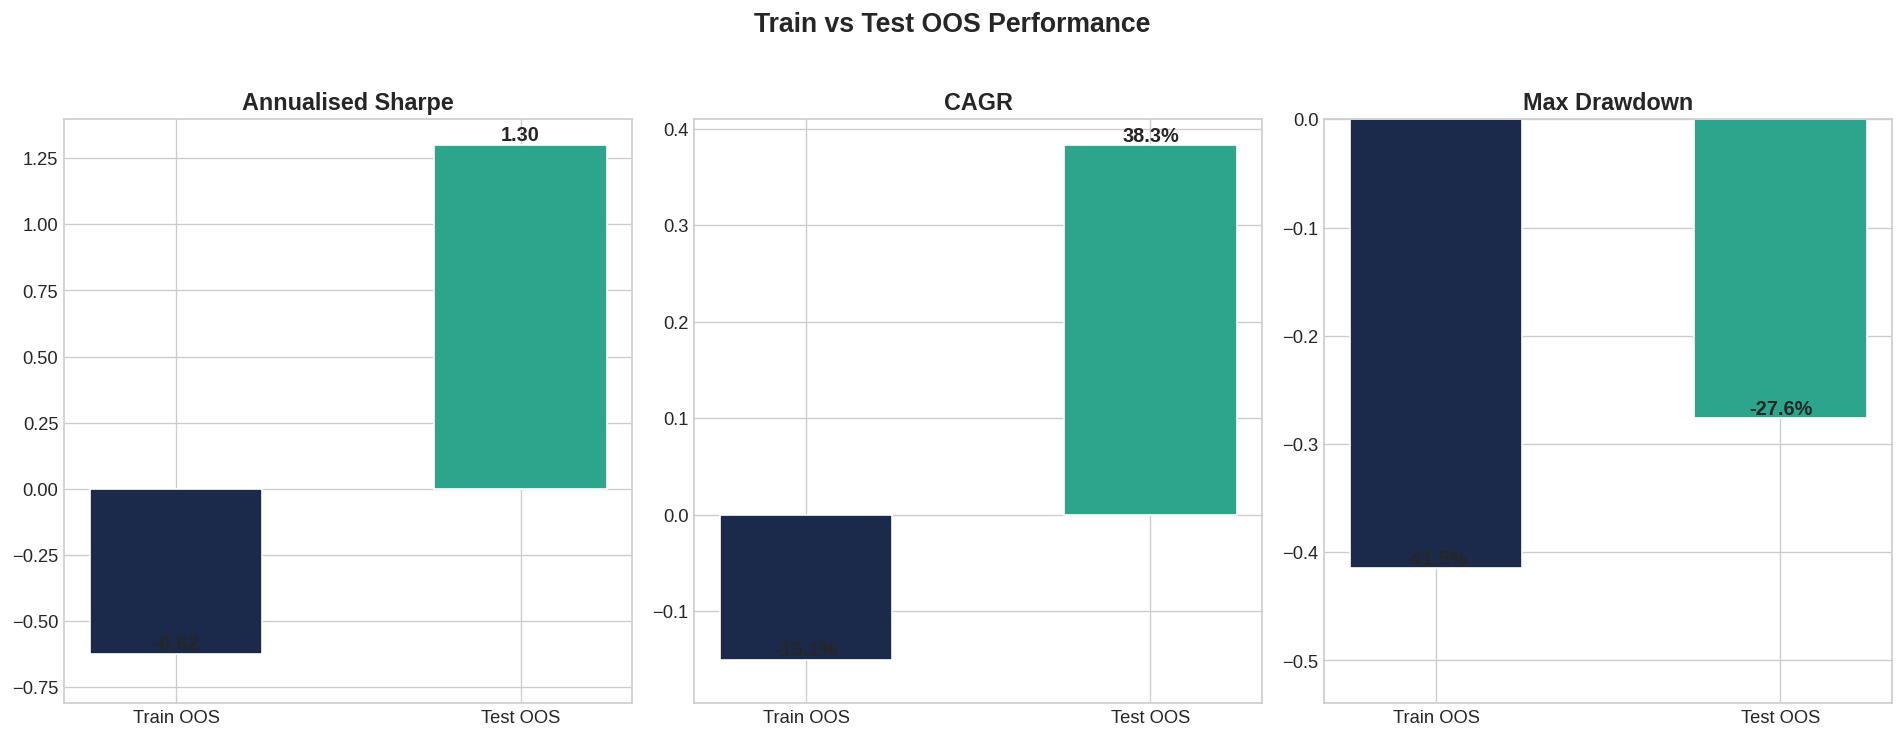

In [7]:
fig = plot_train_test_comparison(diag)
plt.show()

## 4. Statistical significance

A Sharpe ratio is a point estimate from a short sample. Without a measure of its uncertainty there is no way to distinguish skill from luck, and the four tests below attack that problem from different directions.

### 4.1 Circular block bootstrap

Resampling individual months independently would destroy the serial dependence in the return series, and that dependence is precisely what makes the naive standard error wrong. The block bootstrap (Politis and Romano, 1992) resamples contiguous blocks instead, preserving dependence within each block.

The implementation uses six-month blocks wrapped circularly, so the series is treated as a loop and every observation has an equal chance of appearing. The block length is the key parameter and it is a trade-off: blocks that are too short destroy the dependence the method exists to preserve, blocks that are too long reduce the effective number of independent resamples. Six months is chosen to span the dominant autocorrelation in monthly equity returns.

Ten thousand replications give the sampling distribution of the Sharpe ratio, from which a percentile confidence interval follows directly. The width of that interval is usually the most sobering number in the whole project: with roughly 38 test-period months, the 95% interval on a Sharpe ratio is typically wider than one unit.

### A note on the p-value

The p-value reported is the fraction of bootstrap Sharpe ratios at or below zero. This is a convenient approximation rather than a correct hypothesis test, because the bootstrap distribution is centred on the observed Sharpe ratio rather than on the null. A strictly correct version resamples under the null by centring the returns first. The interval is the number to trust here; the p-value should be read as indicative.


In [8]:
print("Running block bootstrap (10,000 replications)...\n")

boot_full = SignificanceTests.circular_block_bootstrap_sharpe(
    wf_result['full_oos_returns'],
    n_bootstrap=N_BOOTSTRAP, block_size=BLOCK_SIZE, rf_annual=RF_ANNUAL,
)
boot_test = SignificanceTests.circular_block_bootstrap_sharpe(
    wf_result['oos_returns_test'],
    n_bootstrap=N_BOOTSTRAP, block_size=BLOCK_SIZE, rf_annual=RF_ANNUAL,
)

print(f"{'':25} {'Full OOS':>14} {'Test Only':>14}")
print(f"{'-'*53}")
print(f"{'Sharpe':<25} {boot_full['point_estimate']:>13.2f} {boot_test['point_estimate']:>13.2f}")
print(f"{'95% CI lower':<25} {boot_full['ci_lower']:>13.2f} {boot_test['ci_lower']:>13.2f}")
print(f"{'95% CI upper':<25} {boot_full['ci_upper']:>13.2f} {boot_test['ci_upper']:>13.2f}")
print(f"{'Bootstrap SE':<25} {boot_full['se']:>13.2f} {boot_test['se']:>13.2f}")
print(f"{'p-value (H0: SR≤0)':<25} {boot_full['p_value']:>13.4f} {boot_test['p_value']:>13.4f}")

Running block bootstrap (10,000 replications)...



                                Full OOS      Test Only
-----------------------------------------------------
Sharpe                             0.56          1.32
95% CI lower                      -0.31          0.24
95% CI upper                       1.67          2.74
Bootstrap SE                       0.50          0.64
p-value (H0: SR≤0)               0.1077        0.0071


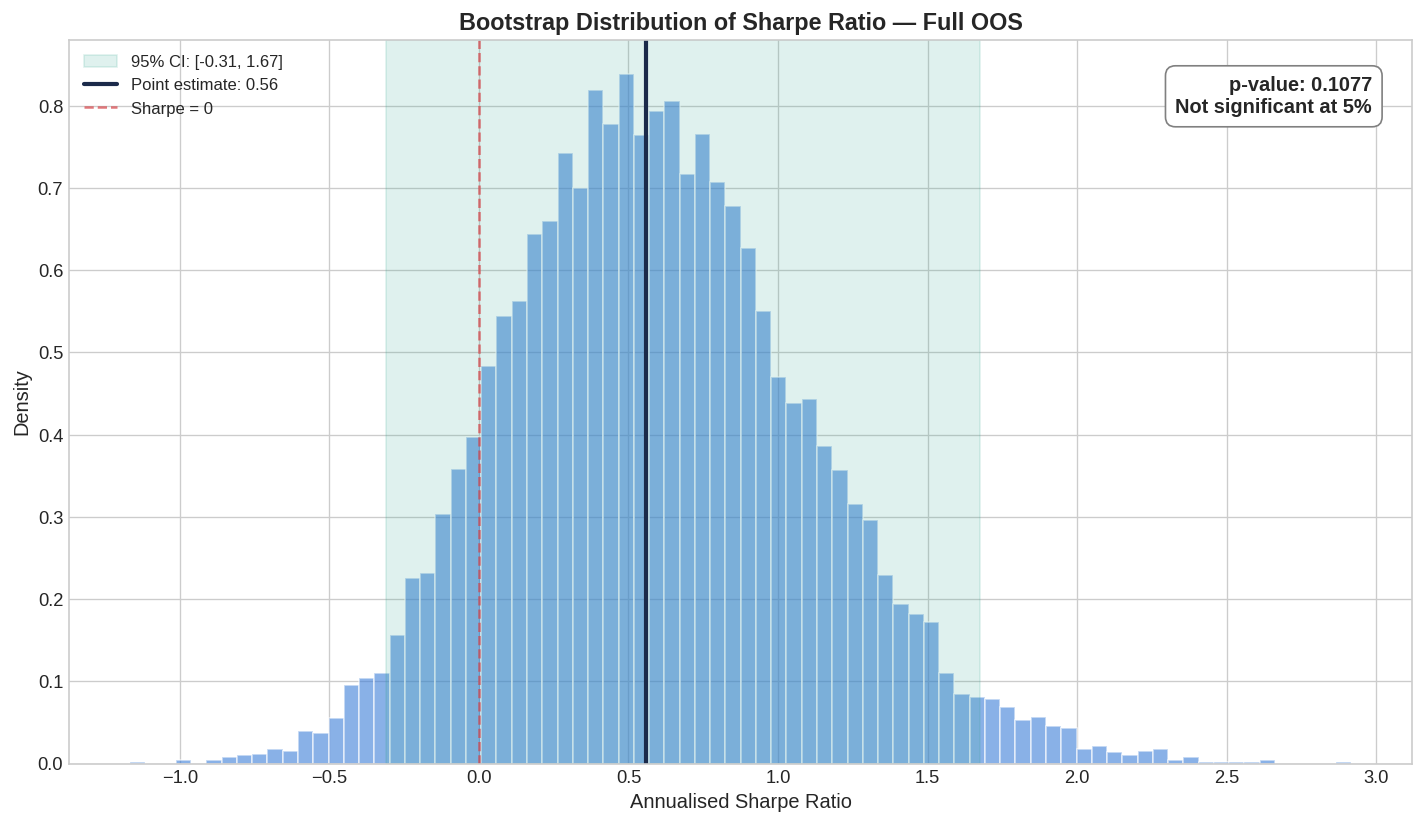

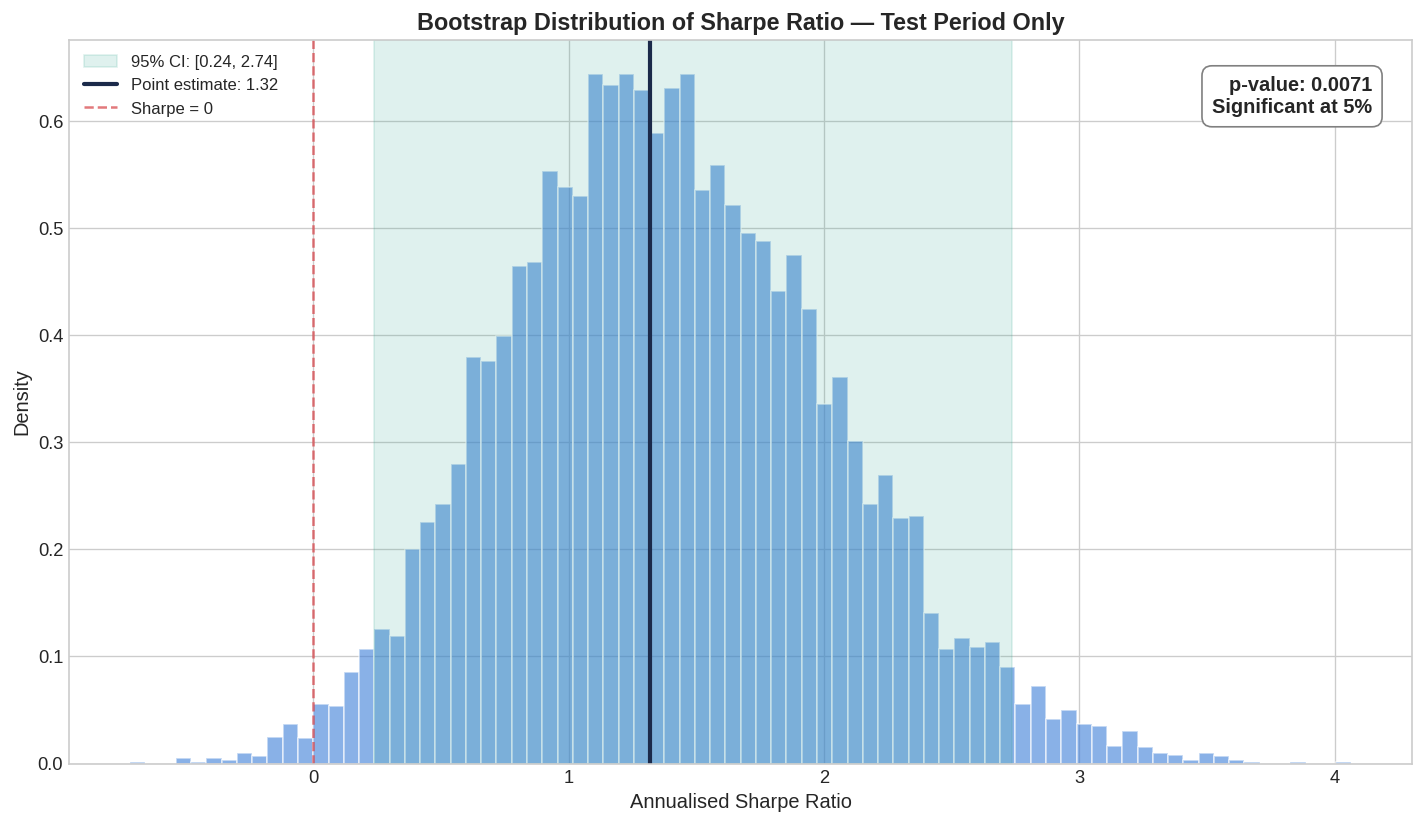

In [9]:
fig = plot_bootstrap_sharpe(boot_full, strategy_name='Full OOS')
plt.show()

fig = plot_bootstrap_sharpe(boot_test, strategy_name='Test Period Only')
plt.show()

### 4.2 Probabilistic Sharpe Ratio

Bailey and Lopez de Prado (2012) ask a sharper question than "is the Sharpe ratio positive": what is the probability that the true Sharpe ratio exceeds a benchmark, given the sample length and the shape of the return distribution?

$$\widehat{\mathrm{PSR}}(\mathrm{SR}^*) = \Phi\!\left(\frac{(\widehat{\mathrm{SR}} - \mathrm{SR}^*)\sqrt{T-1}}{\sqrt{1 - \gamma_3\widehat{\mathrm{SR}} + \frac{\gamma_4 - 1}{4}\widehat{\mathrm{SR}}^2}}\right)$$

The denominator is what makes this better than a $t$-test. It is the standard error of the Sharpe ratio estimator under non-normal returns, and it contains both skewness $\gamma_3$ and kurtosis $\gamma_4$.

Read the signs. Negative skew raises the standard error and lowers the PSR, which is the correct treatment of a strategy that makes steady small gains and occasional large losses, since that return profile flatters the Sharpe ratio while hiding the risk. High kurtosis does the same. The statistic formalises the intuition that a Sharpe ratio earned from a short-volatility-shaped return stream deserves less credence than the same number earned from a symmetric one.

### A convention error, found and fixed

The formula requires $\gamma_4$ as raw kurtosis, where a normal distribution gives 3. The original implementation passed `pandas.Series.kurtosis()`, which returns Fisher excess kurtosis, where a normal gives 0. The term $(\gamma_4 - 1)/4$ therefore evaluated to $-0.25$ under normality instead of $+0.5$.

The effect was to understate the standard error and overstate the PSR, with the bias growing as $\widehat{\mathrm{SR}}^2$ because that is what the term multiplies. It is corrected below by adding 3.

The reason this is worth a paragraph rather than a silent commit is that it is invisible in output. The erroneous standard error is positive, finite, and of entirely plausible magnitude, so the resulting PSR looks like a number rather than like a bug. Nothing in the result signals the problem, and the only defence is checking the convention of every library function whose output feeds a formula taken from a paper. Skewness has the same hazard: `pandas` returns the adjusted Fisher-Pearson coefficient, not the raw third standardised moment, and for small samples those differ.


In [10]:
psr_full = SignificanceTests.probabilistic_sharpe_ratio(
    wf_result['full_oos_returns'], sr_benchmark=0.0, rf_annual=RF_ANNUAL,
)
psr_test = SignificanceTests.probabilistic_sharpe_ratio(
    wf_result['oos_returns_test'], sr_benchmark=0.0, rf_annual=RF_ANNUAL,
)

print("Probabilistic Sharpe Ratio")
print(f"{'='*53}")
print(f"  {'':25} {'Full OOS':>12} {'Test Only':>12}")
print(f"  {'-'*49}")
print(f"  {'PSR':<25} {psr_full['psr']:>11.4f} {psr_test['psr']:>11.4f}")
print(f"  {'z-stat':<25} {psr_full['z_stat']:>11.2f} {psr_test['z_stat']:>11.2f}")
print(f"  {'Sharpe (ann.)':<25} {psr_full['sr_hat_annual']:>11.2f} {psr_test['sr_hat_annual']:>11.2f}")
print(f"  {'Skewness':<25} {psr_full['skewness']:>11.2f} {psr_test['skewness']:>11.2f}")
print(f"  {'Excess Kurtosis':<25} {psr_full['excess_kurtosis']:>11.2f} {psr_test['excess_kurtosis']:>11.2f}")
print(f"  {'Significant (5%)':<25} {'Yes' if psr_full['significant'] else 'No':>12} "
      f"{'Yes' if psr_test['significant'] else 'No':>12}")

Probabilistic Sharpe Ratio
                                Full OOS    Test Only
  -------------------------------------------------
  PSR                            0.8830      0.9733
  z-stat                           1.19        1.93
  Sharpe (ann.)                    0.56        1.32
  Skewness                        -0.57       -0.78
  Excess Kurtosis                 -0.23        0.79
  Significant (5%)                    No          Yes


### 4.3 Deflated Sharpe Ratio

If several strategies are tested and only the winner is reported, the winner's Sharpe ratio is biased upward even when every strategy has zero true edge. This is the multiple-testing problem, and in backtesting it is the dominant source of false discoveries.

The Deflated Sharpe Ratio (Bailey and Lopez de Prado, 2014) handles it by replacing the benchmark in the PSR with the Sharpe ratio one would expect from the best of $N$ independent trials of a strategy with no skill:

$$\mathbb{E}\left[\max_{i \le N} \mathrm{SR}_i\right] \approx \sigma_{\mathrm{SR}}\left[(1-\gamma)\,\Phi^{-1}\!\left(1 - \tfrac{1}{N}\right) + \gamma\,\Phi^{-1}\!\left(1 - \tfrac{1}{Ne}\right)\right]$$

where $\gamma \approx 0.5772$ is the Euler-Mascheroni constant. The expression comes from extreme value theory: the maximum of $N$ draws from a Gaussian grows like $\sqrt{2\ln N}$, slowly but without bound. Test enough strategies and something will look excellent.

### The trial count is the hard part

$N$ is set to 4 below, counting the four optimisation methods compared. That number is far too low, and I want to be explicit about why rather than let the deflated figure stand unqualified.

The honest trial count includes every decision made while building this, not just the four variants presented at the end. The lookback length, the rebalancing frequency, the weight cap, the universe size, the shrinkage choice, the embargo length, the block size: each was selected from a set of plausible alternatives, and each selection is a test. The effective search space is not 4, it is the product of those option sets, and it runs well into the thousands.

Worse, those choices are nested rather than independent. The number of specifications does not add across the layers of the model, it multiplies. A model with roughly 40 plausible estimation settings, 60 plausible universe constructions and 200 plausible signal variants represents a search space in the hundreds of thousands, of which exactly one gets written up.

With $N = 4$ the deflation term is small and the DSR is close to the PSR. With $N$ in the thousands it would be substantially larger, since the term grows as $\sqrt{2 \ln N}$. The figure below is therefore a lower bound on the correct deflation, and I report it as such. This is a problem I am taking up properly as a separate piece of research.

### $\sigma_{\mathrm{SR}}$, and a bug that ran the other way

The benchmark scales with $\sigma_{\mathrm{SR}}$, the dispersion of Sharpe ratio estimates across trials. The original implementation set it to one in monthly units. For a 37-month sample the standard error of a Sharpe estimate under the null is $\sqrt{1/(T-1)} \approx 0.17$, so the benchmark was inflated roughly six-fold: it reported an expected maximum Sharpe ratio of 3.64 for four trials of a strategy with no skill, and the DSR came out at essentially zero regardless of the strategy.

I had initially described that simplification as optimistic. It was the reverse, and by a large margin. The corrected version uses the null standard error by default, or the sample dispersion of the trial Sharpe ratios when they are supplied, and gives a benchmark of 0.61 for the test period. The lesson is general: a statistic that rejects everything is as uninformative as one that rejects nothing, and an implausible benchmark value is the cheapest available check that the formula has been implemented in the right units.

In [11]:
N_STRATEGIES_TESTED = 4  # MaxSharpe_LW, MaxSharpe_Sample, MinVar, EqualWeight

dsr_full = SignificanceTests.deflated_sharpe_ratio(
    wf_result['full_oos_returns'], n_strategies_tested=N_STRATEGIES_TESTED, rf_annual=RF_ANNUAL,
)
dsr_test = SignificanceTests.deflated_sharpe_ratio(
    wf_result['oos_returns_test'], n_strategies_tested=N_STRATEGIES_TESTED, rf_annual=RF_ANNUAL,
)

print("Deflated Sharpe Ratio (multiple-testing corrected)")
print(f"{'='*53}")
print(f"  Strategies tested: {N_STRATEGIES_TESTED}")
print(f"  Expected max Sharpe under null (annualised):")
print(f"    full OOS  : {dsr_full['sr_benchmark_annual']:.2f}   (sigma_SR {dsr_full['sigma_sr_monthly']:.3f}/month, T={len(wf_result['full_oos_returns'])})")
print(f"    test only : {dsr_test['sr_benchmark_annual']:.2f}   (sigma_SR {dsr_test['sigma_sr_monthly']:.3f}/month, T={len(wf_result['oos_returns_test'])})")
print(f"  {'':25} {'Full OOS':>12} {'Test Only':>12}")
print(f"  {'-'*49}")
print(f"  {'DSR':<25} {dsr_full['psr']:>11.4f} {dsr_test['psr']:>11.4f}")
print(f"  {'Significant (5%)':<25} {'Yes' if dsr_full['significant'] else 'No':>12} "
      f"{'Yes' if dsr_test['significant'] else 'No':>12}")

Deflated Sharpe Ratio (multiple-testing corrected)
  Strategies tested: 4
  Expected max Sharpe under null (annualised):
    full OOS  : 0.47   (sigma_SR 0.129/month, T=61)
    test only : 0.61   (sigma_SR 0.167/month, T=37)
                                Full OOS    Test Only
  -------------------------------------------------
  DSR                            0.5746      0.8512
  Significant (5%)                    No           No


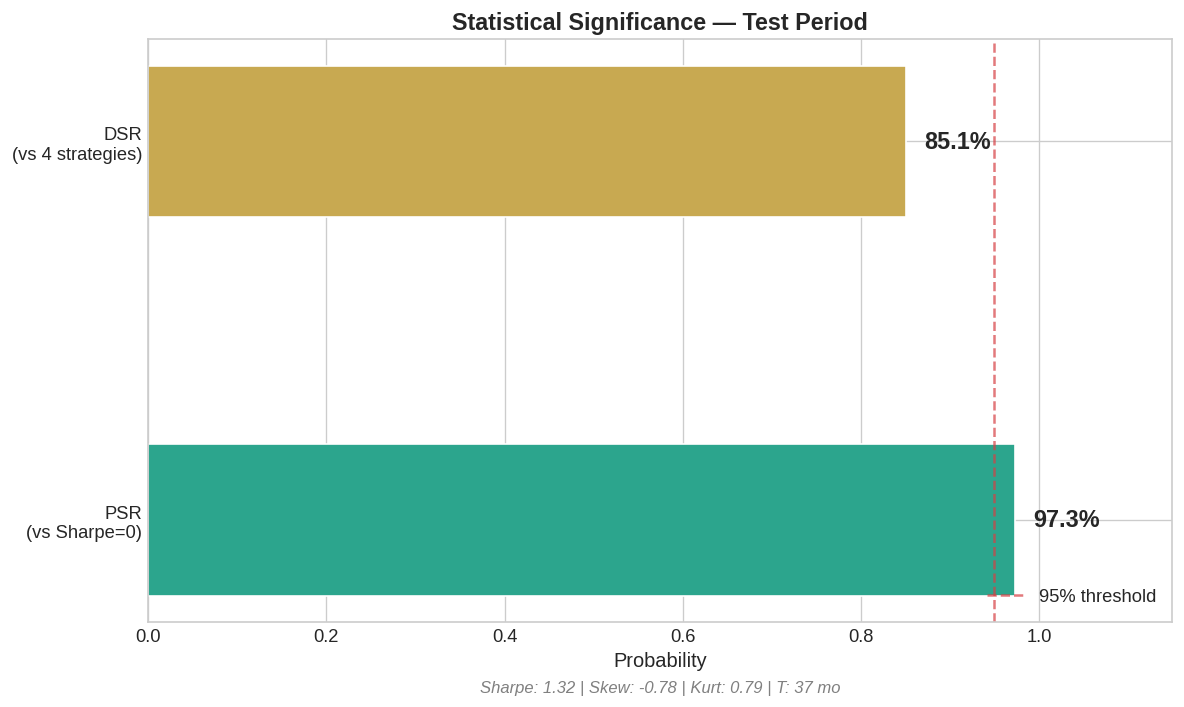

In [12]:
fig = plot_psr_summary(psr_test, dsr_test, title='Statistical Significance — Test Period')
plt.show()

### 4.4 Harvey-Liu Sharpe haircut

A simpler correction in the same spirit, from Harvey and Liu (2015):

$$\mathrm{SR}_{\mathrm{adj}} \approx \mathrm{SR}_{\mathrm{obs}} - \frac{\sqrt{2\ln N}}{\sqrt{T/12}}$$

The numerator is the asymptotic growth rate of the maximum of $N$ standard normals. The denominator converts to the sample length in years, since the standard error of an estimated Sharpe ratio shrinks with the square root of elapsed time.

It is cruder than the DSR, assuming independent trials and normal returns, and it is useful precisely because it is crude. It makes the trade-off legible: the haircut rises slowly in the number of trials and falls slowly in the length of the sample, which means a short backtest can never be rescued by testing fewer things. Reporting it alongside the DSR provides a sanity check on a more complicated calculation.


In [13]:
haircut = OverfitDiagnostics.sharpe_ratio_haircuts(
    observed_sharpe=diag['test_sharpe'],
    n_months=diag['test_months'],
    n_strategies=N_STRATEGIES_TESTED,
)

print(f"Harvey-Liu Sharpe Haircut")
print(f"{'='*40}")
print(f"  Observed Sharpe:  {haircut['observed']:.2f}")
print(f"  Haircut:          {haircut['haircut']:.2f} ({haircut['haircut_pct']:.0f}%)")
print(f"  Adjusted Sharpe:  {haircut['adjusted']:.2f}")

Harvey-Liu Sharpe Haircut
  Observed Sharpe:  1.30
  Haircut:          0.95 (73%)
  Adjusted Sharpe:  0.35


## 5. Strategy comparison

Four strategies plus the benchmark, run on identical data through identical machinery, then compared with a paired bootstrap.

The pairing matters. Testing each strategy's Sharpe ratio against zero separately and declaring the higher one the winner ignores that the two series are computed on the same months and are therefore highly correlated. The paired test resamples the same blocks for both series simultaneously and takes the distribution of the difference, which is a far more powerful test of the question actually being asked.

Equal weighting is included as a strategy and not as a formality. DeMiguel, Garlappi and Uppal (2009) tested fourteen optimisation approaches across multiple datasets and found that none of them consistently beat $1/N$ out of sample. Their explanation is that the estimation error in the expected return vector overwhelms the theoretical benefit of optimising, and that it would take several centuries of monthly data for the optimisation to pay for its own estimation error at realistic parameter values. Any optimised portfolio that does not clear equal weighting here has not demonstrated anything.


In [14]:
print("Running strategy suite...")
strategy_rets = run_strategy_suite(
    monthly_returns, portfolio_tickers,
    benchmark_col=BENCHMARK, lookback=LOOKBACK_MONTHS, rf=RF_ANNUAL,
)

test_start_ts = pd.Timestamp(TEST_START)
test_rets = {name: r[r.index >= test_start_ts] for name, r in strategy_rets.items()}

print("\n=== TEST PERIOD PERFORMANCE ===")
test_metrics = compare_strategies(test_rets, RF_ANNUAL)
print(test_metrics[['CAGR', 'Volatility', 'Sharpe', 'Sortino', 'Max DD']].to_string(
    float_format='{:.3f}'.format))

Running strategy suite...



=== TEST PERIOD PERFORMANCE ===
                  CAGR  Volatility  Sharpe  Sortino  Max DD
MaxSharpe_LW     0.403       0.213   1.514    1.898  -0.230
MaxSharpe_Sample 0.366       0.201   1.454    1.774  -0.221
MinVar_LW        0.187       0.172   0.831    1.499  -0.133
EqualWeight      0.350       0.192   1.443    3.417  -0.127
SPY              0.200       0.116   1.263    2.565  -0.083


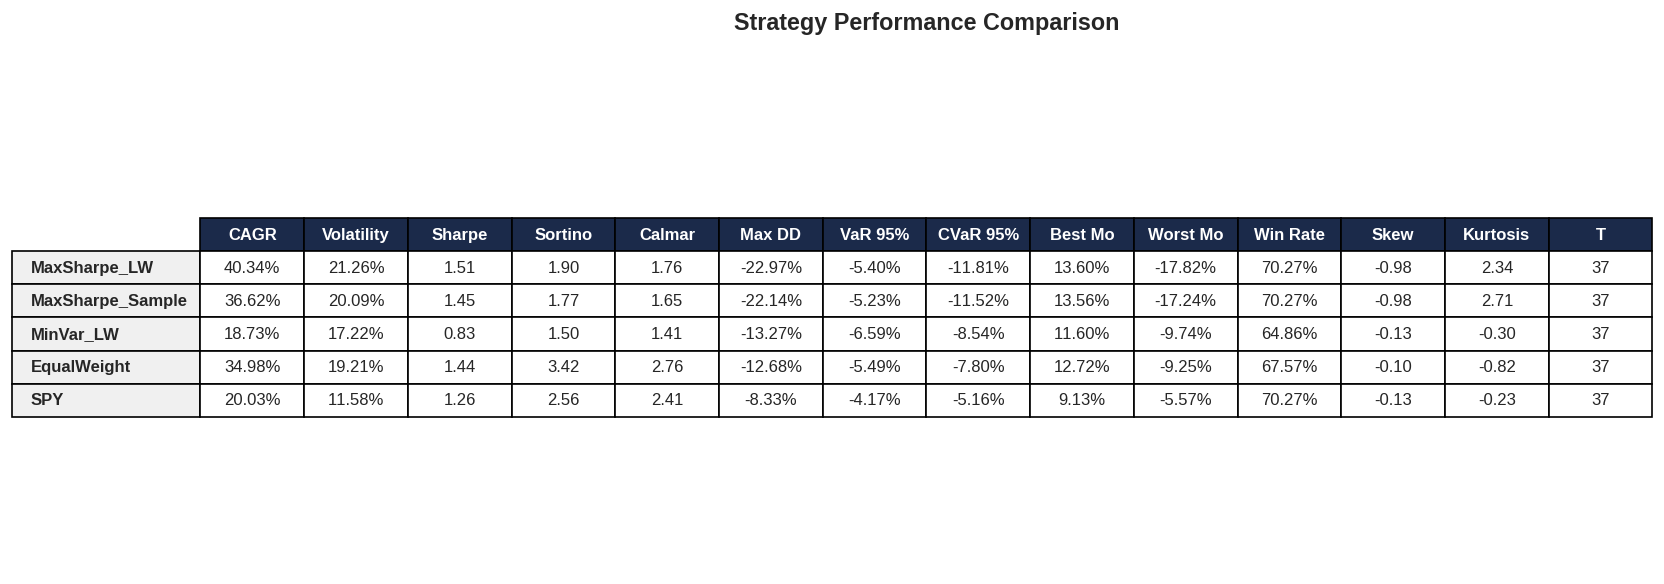

In [15]:
fig = plot_strategy_comparison_table(test_metrics)
plt.show()

### 5.1 Paired bootstrap against the benchmark

The null hypothesis is that the Sharpe ratio difference between the best strategy and SPY is zero. The test resamples blocks jointly from both series, recomputes the difference ten thousand times, and takes the two-sided p-value from the resulting distribution.

Expect a wide interval. Over roughly 38 test months, the difference in Sharpe ratios between two correlated equity portfolios is rarely distinguishable from zero at conventional levels, and reporting that honestly is more useful than finding a specification that clears 5%.


In [16]:
best_key = test_metrics.drop('SPY', errors='ignore')['Sharpe'].idxmax()

if 'SPY' in test_rets and best_key in test_rets:
    paired = SignificanceTests.paired_bootstrap_test(
        test_rets[best_key], test_rets['SPY'],
        n_bootstrap=N_BOOTSTRAP, block_size=BLOCK_SIZE,
    )
    
    print(f"Paired Bootstrap: {best_key} vs SPY (Test Period)")
    print(f"{'='*50}")
    print(f"  {best_key} Sharpe:  {paired['sharpe_a']:.2f}")
    print(f"  SPY Sharpe:         {paired['sharpe_b']:.2f}")
    print(f"  Difference:         {paired['observed_diff']:.2f}")
    print(f"  95% CI:             [{paired['ci_lower']:.2f}, {paired['ci_upper']:.2f}]")
    print(f"  p-value:            {paired['p_value']:.4f}")
    print(f"  Significant (5%):   {'Yes' if paired['significant_5pct'] else 'No'}")

Paired Bootstrap: MaxSharpe_LW vs SPY (Test Period)
  MaxSharpe_LW Sharpe:  1.53
  SPY Sharpe:         1.28
  Difference:         0.25
  95% CI:             [-0.42, 1.19]
  p-value:            0.5012
  Significant (5%):   No


## 6. Weight evolution

The weight path over the test period is a stability diagnostic, not a performance one.

Mean-variance optimisers are notoriously unstable: small changes in estimated expected returns produce large changes in weights, because the solution depends on the inverse covariance matrix. If the weight path jumps sharply month to month, the strategy is tracking estimation noise rather than a signal, and two things follow. The turnover is high, so transaction costs eat the return. And the realised portfolio is not the portfolio whose statistics were reported, because no one holds a position long enough for its expected properties to materialise.

The 15% cap damps this. Watching how often the cap binds indicates how extreme the unconstrained solution wanted to be, which is itself a measure of how unreliable the inputs are.


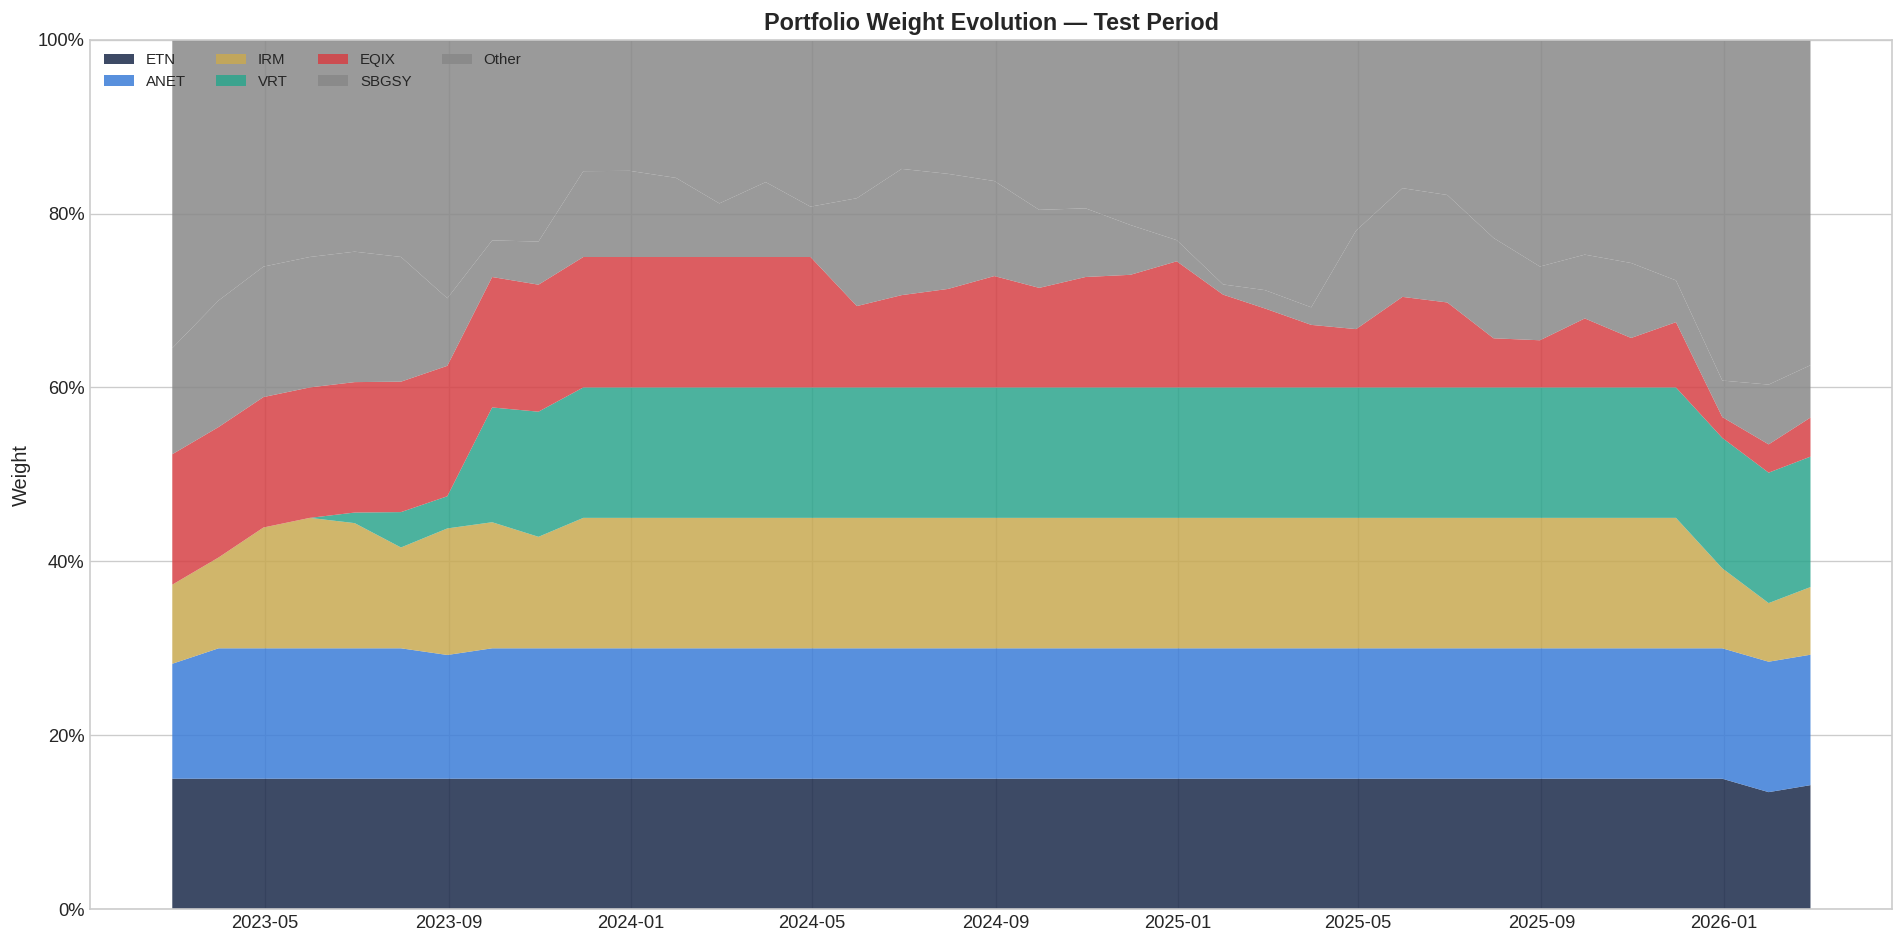

In [17]:
test_weights = wf_result['weights_test']
test_dates = wf_result['oos_returns_test'].index

if test_weights:
    fig = plot_weight_evolution(test_weights, test_dates,
                                title='Portfolio Weight Evolution — Test Period')
    plt.show()

## 7. Risk analysis

VaR and CVaR on the test-period return series, at 90%, 95% and 99%.

Two limitations specific to this section. These are monthly returns, so a 99% monthly VaR is being estimated from roughly 38 observations, which means the 99% figure is effectively the worst month in the sample and carries essentially no information about the tail beyond it. Extreme value theory, fitting a Generalised Pareto distribution above a threshold, is the appropriate tool at that confidence level and is not implemented here.

Second, these figures are computed on test-period data only. That is correct for the purpose, since using the full sample would reintroduce the information the split exists to exclude, but it means the risk estimates rest on a short and unusually calm window.


In [18]:
test_oos = wf_result['oos_returns_test']

print("VaR & CVaR — Test Period (Monthly)")
print(var_analysis(test_oos).to_string(float_format='{:.2%}'.format))

print(f"\nAvg monthly turnover (test): {wf_result['turnover_test'].mean():.2%}")

VaR & CVaR — Test Period (Monthly)
            Hist VaR  Hist CVaR  Gauss VaR
Confidence                                
90%           -5.36%    -10.19%     -5.93%
95%           -7.54%    -13.70%     -8.46%
99%          -14.87%    -17.88%    -13.20%

Avg monthly turnover (test): 5.96%


## 8. Summary

All figures are test-period only, February 2023 to February 2026, and net of 15 bps round-trip transaction costs.

| Question | Answer |
|---|---|
| Is the Sharpe ratio positive? | Probably. 1.30, bootstrap 95% interval [0.24, 2.74], PSR 0.97 |
| Does it survive multiple testing? | No. DSR 0.85 against an expected maximum of 0.61 for four trials, and four is a severe undercount |
| Does it beat the market? | Not detectably. Paired difference against SPY 0.25, p = 0.50 |
| Does optimisation add anything? | Not here. Equal weighting reached a Sharpe ratio of 1.44 against 1.51 for the best optimised variant |
| Did it decay out of sample? | It improved, from -0.62 to 1.30, which reflects the regimes in each window more than the strategy |

The honest reading is that the theme performed well over this test window, a simple equal-weighted holding of it would have captured nearly all of that, and nothing here establishes that the optimisation layer contributed skill. That is a normal result for mean-variance optimisation on 85 monthly observations, and it is the result DeMiguel, Garlappi and Uppal would predict.

The PSR figures use the corrected kurtosis convention and the DSR uses the corrected $\sigma_{\mathrm{SR}}$; both corrections are described where they occur.

In [19]:
print("\n" + "="*70)
print("  FINAL RESULTS — TEST PERIOD OUT-OF-SAMPLE")
print("="*70)
print(f"  Test Period:          {test_oos.index[0].strftime('%Y-%m')} to {test_oos.index[-1].strftime('%Y-%m')}")
print(f"  CAGR:                 {diag['test_cagr']:.2%}")
print(f"  Sharpe Ratio:         {diag['test_sharpe']:.2f}")
print(f"  Sharpe 95% CI:        [{boot_test['ci_lower']:.2f}, {boot_test['ci_upper']:.2f}]")
print(f"  PSR (vs Sharpe=0):    {psr_test['psr']:.4f} ({'significant' if psr_test['significant'] else 'NOT significant'})")
print(f"  DSR ({N_STRATEGIES_TESTED} strategies):   {dsr_test['psr']:.4f} ({'significant' if dsr_test['significant'] else 'NOT significant'})")
print(f"  Adjusted Sharpe:      {haircut['adjusted']:.2f} (Harvey-Liu haircut)")
print(f"  Max Drawdown:         {diag['test_max_dd']:.2%}")
if diag['sharpe_decay'] is not None:
    print(f"  Sharpe Decay:         {diag['sharpe_decay']:.2%}")
print(f"  Avg Monthly Turnover: {diag['test_turnover_avg']:.2%}")
print("="*70)
print("  Note: All figures NET of 15 bps round-trip transaction costs.")
print("="*70)


  FINAL RESULTS — TEST PERIOD OUT-OF-SAMPLE
  Test Period:          2023-02 to 2026-02
  CAGR:                 38.32%
  Sharpe Ratio:         1.30
  Sharpe 95% CI:        [0.24, 2.74]
  PSR (vs Sharpe=0):    0.9733 (significant)
  DSR (4 strategies):   0.8512 (NOT significant)
  Adjusted Sharpe:      0.35 (Harvey-Liu haircut)
  Max Drawdown:         -27.59%
  Avg Monthly Turnover: 5.96%
  Note: All figures NET of 15 bps round-trip transaction costs.


---

## Where this goes next

**Combinatorial purged cross-validation.** A single train/test split is one draw. CPCV (Bailey et al., 2017) generates many train/test partitions with purging and embargoing applied throughout, producing a distribution of out-of-sample Sharpe ratios rather than a point. It also yields the Probability of Backtest Overfitting directly, which is the quantity the single split only gestures at.

**An honest trial count.** The deflation in 4.3 is only as good as $N$, and $N = 4$ is wrong by orders of magnitude. Counting trials properly for a model built in layers, where specifications multiply rather than add, is an open problem and the subject of separate work.

**Regime-conditional allocation.** A hidden Markov model on the return series would let the allocation differ between volatility states instead of being optimised for their average. Built as its own project.

**A market-capitalisation prior for Black-Litterman.** The research notebook still uses an equal-weighted prior, which removes the equilibrium argument that justifies the model. Fixing it requires a share-count series the data loader does not yet fetch.